## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split as tts
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv('anime_top_clean.csv')
df

,title,type,episodes,score,members
0,Sousou no Frieren,TV,28.0,9.24,1540103
1,Fullmetal Alchemist: Brotherhood,TV,64.0,9.11,3753044
2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,TV,19.0,9.07,367248
3,Steins;Gate,TV,24.0,9.07,2864729
4,Shingeki no Kyojin Season 3 Part 2,TV,10.0,9.06,2655133
...,...,...,...,...,...
195,Grand Blue,TV,12.0,8.45,934790
196,Mo Dao Zu Shi: Xian Yun Pian,ONA,8.0,8.45,120982
197,Owarimonogatari,TV,12.0,8.45,517694
198,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,Movie,1.0,8.45,654243


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   title     200 non-null    str    
 1   type      200 non-null    str    
 2   episodes  195 non-null    float64
 3   score     200 non-null    float64
 4   members   200 non-null    int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 7.9 KB


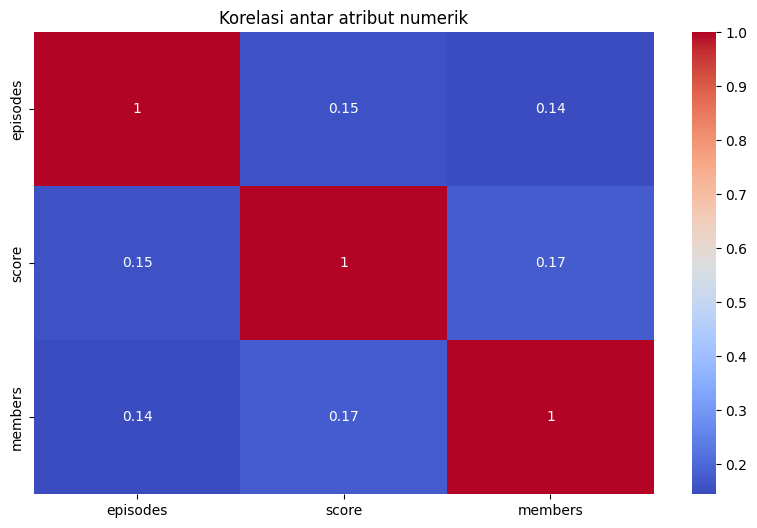

In [4]:
import seaborn as sns

num_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.title("Korelasi antar atribut numerik")
plt.show()

In [5]:
# Langkah 3: buang baris yang punya NaN di kolom yang dipakai
db_clean = df.dropna(subset=["episodes", "members", "score"]).copy()

# Konversi kolom angka ke tipe numerik (jaga-jaga kalau masih object)
db_clean["episodes"] = pd.to_numeric(db_clean["episodes"], errors="coerce")
db_clean["members"]  = pd.to_numeric(db_clean["members"],  errors="coerce")
db_clean["score"]    = pd.to_numeric(db_clean["score"],    errors="coerce")

# Buang NaN hasil konversi
db_clean = db_clean.dropna(subset=["episodes", "members", "score"])

# Langkah 4: tentukan x (fitur, atribut angka lainnya) dan y (target, satu atribut angka)
x = db_clean[["episodes", "members"]]   # 2 fitur
y = db_clean["score"]                    # target

print("Jumlah data setelah dropna:", len(db_clean))
print("Contoh x:")
print(x.head())
print("\nContoh y:")
print(y.head())

Jumlah data setelah dropna: 195
Contoh x:
   episodes  members
0      28.0  1540103
1      64.0  3753044
2      19.0   367248
3      24.0  2864729
4      10.0  2655133

Contoh y:
0    9.24
1    9.11
2    9.07
3    9.07
4    9.06
Name: score, dtype: float64


In [6]:
# Langkah 5: test_size = 0.2, random_state = 0
x_train, x_test, y_train, y_test = tts(x, y, test_size=0.2, random_state=0)

print("Jumlah data latih:", len(x_train))
print("Jumlah data uji  :", len(x_test))

Jumlah data latih: 156
Jumlah data uji  : 39


In [8]:
# Maftuh Faisal_202431163
model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.,0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['episodes','members']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.615
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [9]:
y_pred = model.predict(x_test)
y_pred

array([8.64282943, 8.62319506, 8.67278984, 8.63891273, 8.76458065,
       8.71492071, 8.62678988, 8.81952552, 8.64085695, 8.83354994,
       8.68735417, 8.63978095, 8.66016745, 8.63472363, 8.63230705,
       8.65507058, 8.63412382, 8.64471445, 8.71316476, 8.67535016,
       8.62912639, 8.70783007, 8.64856683, 8.73558185, 8.63278237,
       8.6412583 , 8.62737323, 8.72307498, 8.6784772 , 8.67942928,
       8.73437401, 8.70205881, 8.69568995, 8.6354954 , 8.73304519,
       8.63726698, 8.64224955, 8.70203338, 8.61770045])

In [10]:
# Langkah 9: evaluasi
print("coefficient :", model.coef_)
print("intercept   :", model.intercept_)
print("MSE         :", mean_squared_error(y_test, y_pred))
print("R2 Score    :", r2_score(y_test, y_pred))

coefficient : [8.45111151e-04 4.11325841e-08]
intercept   : 8.61538159709783
MSE         : 0.031312641352212
R2 Score    : -0.016587779068983455


In [11]:
# Maftuh faisal_202431163
a = model.intercept_
b1, b2 = model.coef_

print("Persamaan regresi:")
print(f"Y = {a:.4f} + {b1:.6f}·x1 + {b2:.6f}·x2")
print()
print("Dengan:")
print("  Y  = score (rating anime)")
print("  x1 = episodes (jumlah episode)")
print("  x2 = members (jumlah member/popularitas)")
print()
print(f"Interpretasi:")
print(f"  - Setiap tambahan 1 episode  → score berubah {b1:+.6f}")
print(f"  - Setiap tambahan 1 member   → score berubah {b2:+.8f}")

Persamaan regresi:
Y = 8.6154 + 0.000845·x1 + 0.000000·x2

Dengan:
  Y  = score (rating anime)
  x1 = episodes (jumlah episode)
  x2 = members (jumlah member/popularitas)

Interpretasi:
  - Setiap tambahan 1 episode  → score berubah +0.000845
  - Setiap tambahan 1 member   → score berubah +0.00000004


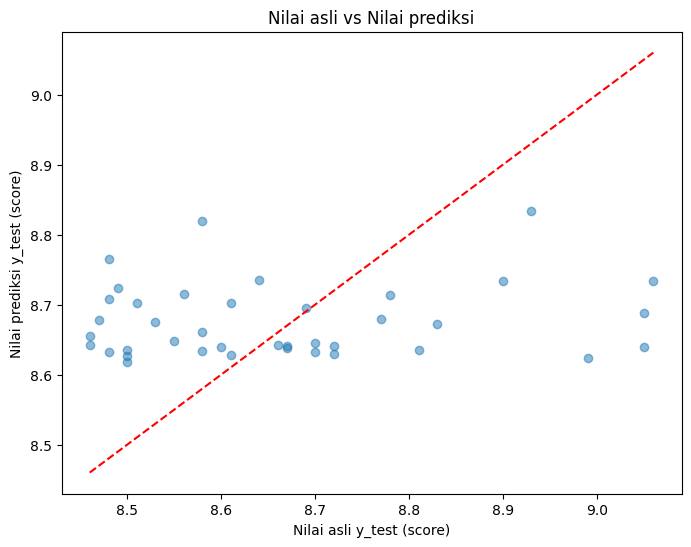

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Nilai asli y_test (score)")
plt.ylabel("Nilai prediksi y_test (score)")
plt.title("Nilai asli vs Nilai prediksi")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.show()